# Cairo Apartment Price Prediction

End-to-end regression pipeline to predict apartment prices (EGP) in Greater Cairo.

**Pipeline:** data generation → cleaning → EDA → feature engineering → model comparison → tuning → evaluation → saved model.

> Note: the dataset here is a **synthetic sample** generated to mimic real Cairo listings (areas, size, rooms, finishing, etc.). The same pipeline runs on real scraped listings by replacing `data/cairo_apartments.csv`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, os
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
np.random.seed(42)
os.makedirs('data', exist_ok=True); os.makedirs('images', exist_ok=True); os.makedirs('models', exist_ok=True)

## 1. Data (synthetic sample of Cairo listings)

In [2]:
areas = {'New Cairo':42000,'Sheikh Zayed':38000,'6th of October':26000,'Maadi':40000,'Zamalek':65000,
         'Heliopolis':35000,'Nasr City':24000,'Mokattam':22000,'Shorouk':20000,'Madinaty':30000}
n = 4000
df = pd.DataFrame({
    'area': np.random.choice(list(areas), n),
    'size_m2': np.random.normal(150, 50, n).clip(55, 400).round(),
    'floor': np.random.randint(0, 15, n),
    'finishing': np.random.choice(['Core & Shell','Semi Finished','Fully Finished','Super Lux'], n, p=[.15,.25,.4,.2]),
    'in_compound': np.random.choice([0,1], n, p=[.45,.55]),
    'age_years': np.random.randint(0, 30, n),
    'has_elevator': np.random.choice([0,1], n, p=[.2,.8]),
    'view': np.random.choice(['Street','Garden','Nile','Pool'], n, p=[.55,.25,.05,.15]),
})
df['bedrooms'] = (df.size_m2/55).round().clip(1,6).astype(int)
df['bathrooms'] = (df.bedrooms - np.random.randint(0,2,n)).clip(1,5)
fin = {'Core & Shell':.75,'Semi Finished':.88,'Fully Finished':1.0,'Super Lux':1.18}
view = {'Street':1,'Garden':1.05,'Nile':1.35,'Pool':1.08}
price = (df.size_m2*df.area.map(areas)*df.finishing.map(fin)*df.view.map(view)
         *(1+.12*df.in_compound)*(1-.008*df.age_years)*(1+.04*df.has_elevator)
         *np.random.lognormal(0,.12,n))
df['price_egp'] = price.round(-3)
# inject real-world noise: missing values & outliers
df.loc[df.sample(frac=.03).index,'floor'] = np.nan
df.loc[df.sample(frac=.02).index,'finishing'] = np.nan
df.loc[df.sample(10).index,'price_egp'] *= 8
df.to_csv('data/cairo_apartments.csv', index=False)
df.head()

,area,size_m2,floor,finishing,in_compound,age_years,has_elevator,view,bedrooms,bathrooms,price_egp
0,Nasr City,92.0,0.0,Fully Finished,0,6,1,Garden,2,2,1861000.0
1,Maadi,156.0,14.0,Fully Finished,0,12,1,Nile,3,3,7278000.0
2,Mokattam,130.0,8.0,Semi Finished,1,25,1,Pool,2,1,2434000.0
3,Zamalek,220.0,1.0,Fully Finished,0,5,1,Garden,4,3,12484000.0
4,Nasr City,225.0,6.0,Fully Finished,1,2,0,Street,4,3,6337000.0


## 2. Cleaning

In [3]:
print(df.isna().sum()[df.isna().sum()>0])
ppm = df.price_egp/df.size_m2
q1,q3 = ppm.quantile([.25,.75]); iqr=q3-q1
mask = ppm.between(q1-3*iqr, q3+3*iqr)
print('Outliers removed:', (~mask).sum())
df = df[mask].reset_index(drop=True)

floor        120
finishing     80
dtype: int64
Outliers removed: 25


## 3. EDA

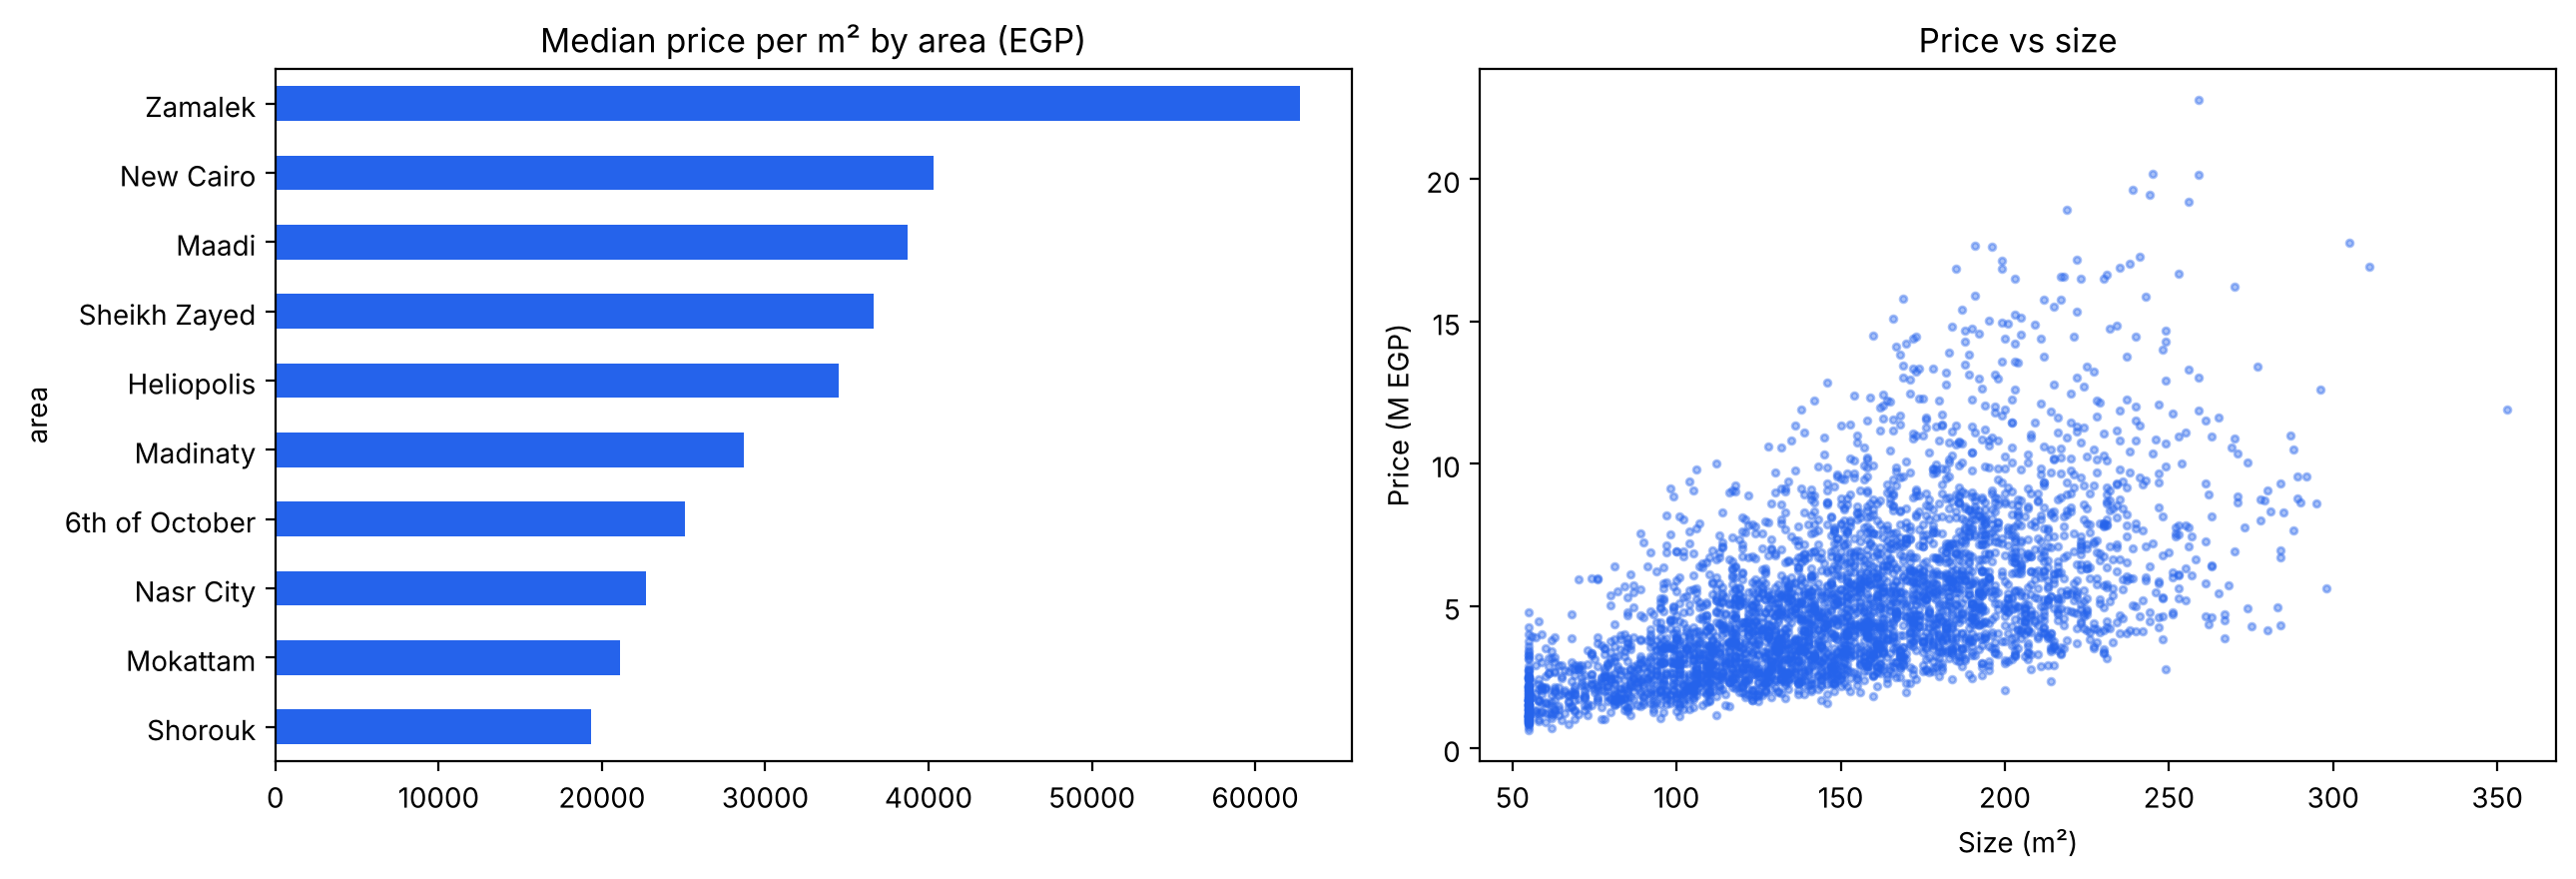

In [4]:
fig,ax = plt.subplots(1,2,figsize=(13,4.5))
(df.assign(ppm=df.price_egp/df.size_m2).groupby('area').ppm.median().sort_values()
   .plot.barh(ax=ax[0],color='#2563eb'))
ax[0].set_title('Median price per m² by area (EGP)')
ax[1].scatter(df.size_m2, df.price_egp/1e6, s=6, alpha=.4, color='#2563eb')
ax[1].set_xlabel('Size (m²)'); ax[1].set_ylabel('Price (M EGP)'); ax[1].set_title('Price vs size')
plt.tight_layout(); plt.savefig('images/eda.png', dpi=120); plt.show()

## 4. Feature engineering & preprocessing

In [5]:
df['rooms_total'] = df.bedrooms + df.bathrooms
df['m2_per_room'] = df.size_m2 / df.bedrooms
X = df.drop(columns='price_egp'); y = np.log1p(df.price_egp)
cat = ['area','finishing','view']
num = [c for c in X.columns if c not in cat]
pre = ColumnTransformer([
    ('num', Pipeline([('imp',SimpleImputer(strategy='median')),('sc',StandardScaler())]), num),
    ('cat', Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('oh',OneHotEncoder(handle_unknown='ignore'))]), cat)])
X_tr,X_te,y_tr,y_te = train_test_split(X,y,test_size=.2,random_state=42)

## 5. Model comparison (5-fold CV)

In [6]:
models = {'Ridge':Ridge(),
          'RandomForest':RandomForestRegressor(n_estimators=200,n_jobs=-1,random_state=42),
          'GradientBoosting':HistGradientBoostingRegressor(random_state=42)}
res = {}
for name,m in models.items():
    s = cross_val_score(Pipeline([('pre',pre),('m',m)]),X_tr,y_tr,cv=5,scoring='r2',n_jobs=-1)
    res[name]=s.mean(); print(f'{name:17s} R² = {s.mean():.3f} ± {s.std():.3f}')

Ridge             R² = 0.927 ± 0.008


RandomForest      R² = 0.913 ± 0.006


GradientBoosting  R² = 0.934 ± 0.005


## 6. Hyperparameter tuning (best model)

In [7]:
search = RandomizedSearchCV(Pipeline([('pre',pre),('m',HistGradientBoostingRegressor(random_state=42))]),
    {'m__learning_rate':[.03,.05,.1],'m__max_iter':[200,400,600],'m__max_depth':[None,6,10],'m__min_samples_leaf':[10,20,40]},
    n_iter=15, cv=5, scoring='r2', random_state=42, n_jobs=-1)
search.fit(X_tr,y_tr); best = search.best_estimator_
print('Best params:', search.best_params_)

Best params: {'m__min_samples_leaf': 20, 'm__max_iter': 200, 'm__max_depth': None, 'm__learning_rate': 0.05}


## 7. Evaluation on test set

MAE  : 498,178 EGP
RMSE : 722,347 EGP
R²   : 0.932
MAPE : 10.2%


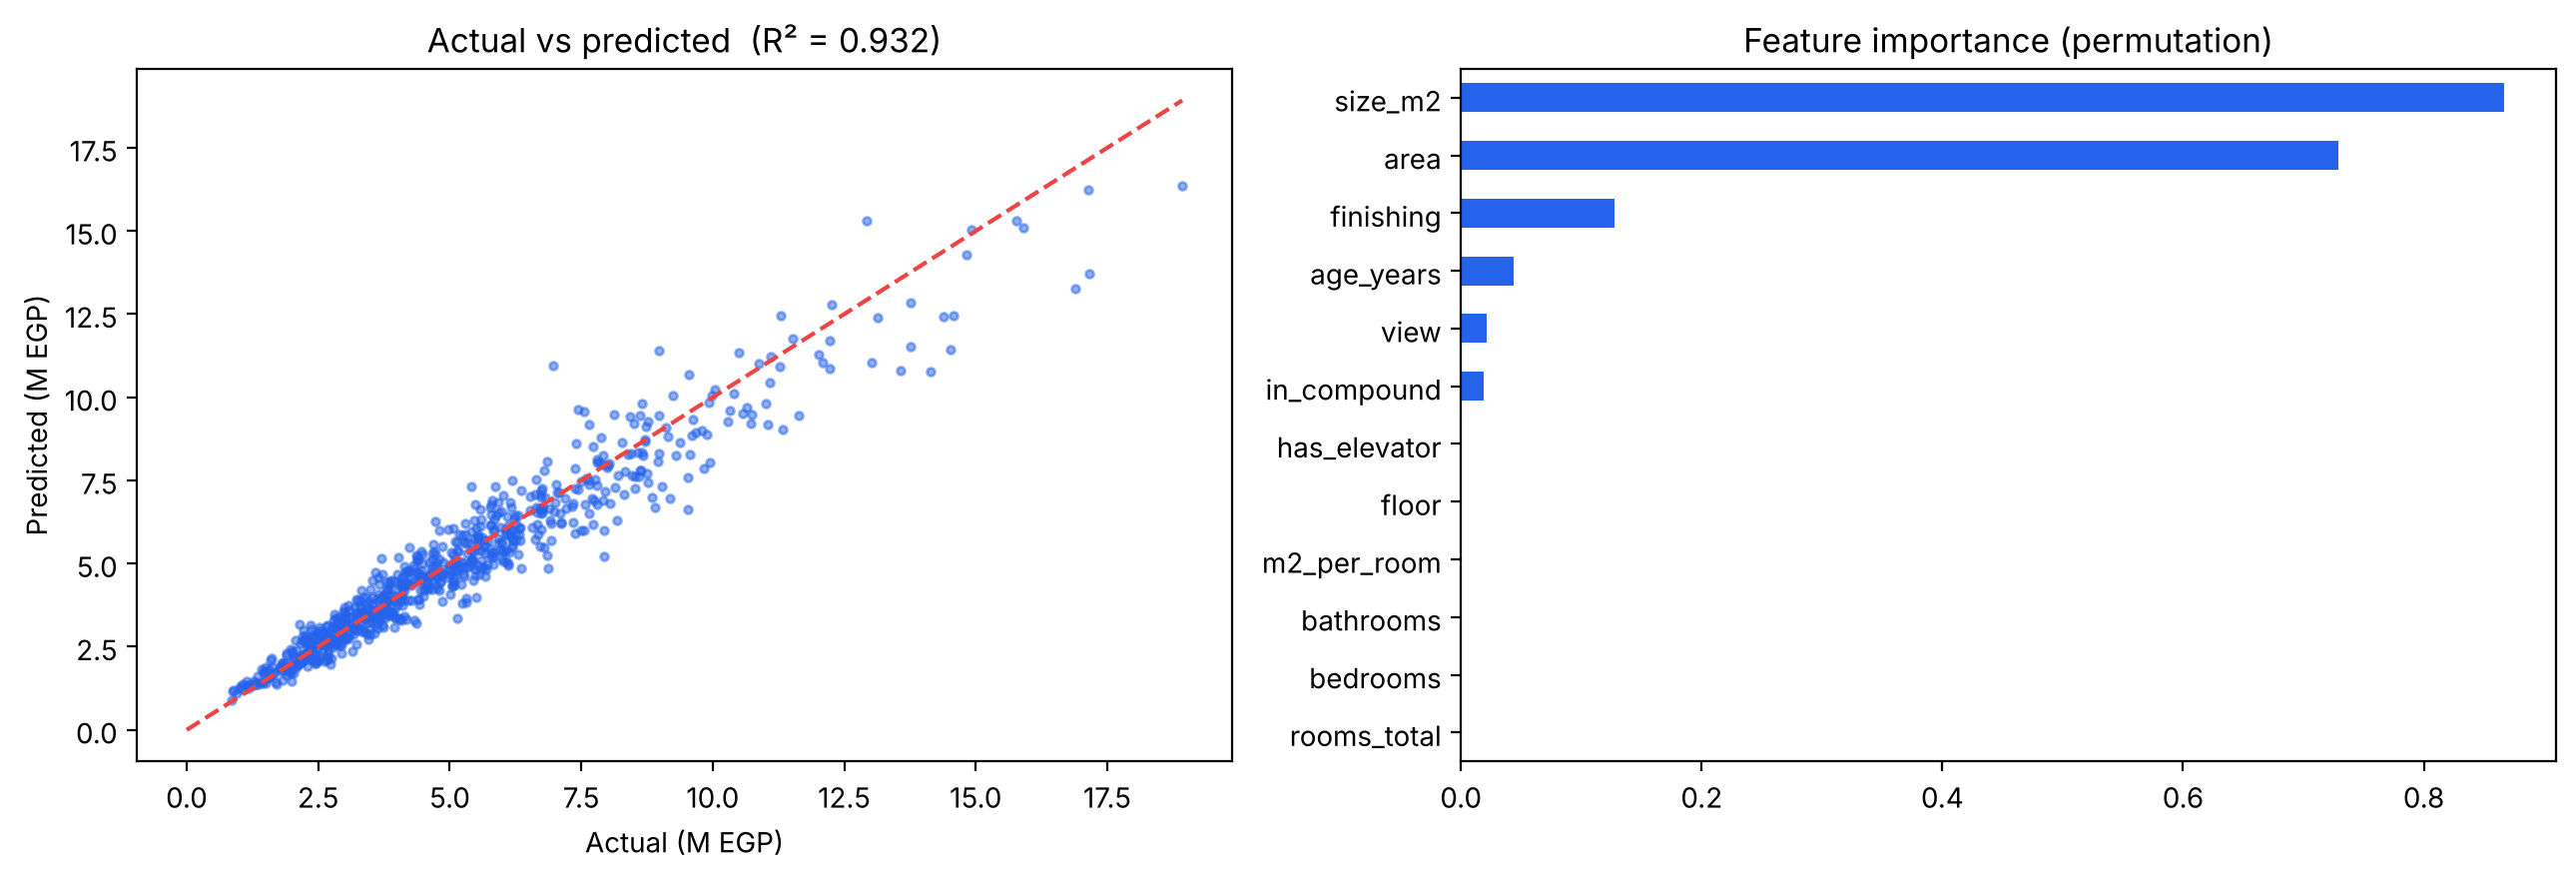

In [8]:
pred = np.expm1(best.predict(X_te)); true = np.expm1(y_te)
mae = mean_absolute_error(true,pred); rmse = mean_squared_error(true,pred)**.5; r2 = r2_score(true,pred)
mape = (abs(true-pred)/true).mean()*100
print(f'MAE  : {mae:,.0f} EGP\nRMSE : {rmse:,.0f} EGP\nR²   : {r2:.3f}\nMAPE : {mape:.1f}%')
fig,ax = plt.subplots(1,2,figsize=(13,4.5))
ax[0].scatter(true/1e6,pred/1e6,s=8,alpha=.5,color='#2563eb'); lim=[0,max(true.max(),pred.max())/1e6]
ax[0].plot(lim,lim,'--',color='#ef4444'); ax[0].set_xlabel('Actual (M EGP)'); ax[0].set_ylabel('Predicted (M EGP)')
ax[0].set_title(f'Actual vs predicted  (R² = {r2:.3f})')
from sklearn.inspection import permutation_importance
pi = permutation_importance(best,X_te,y_te,n_repeats=5,random_state=42,n_jobs=-1)
imp = pd.Series(pi.importances_mean,index=X_te.columns).sort_values()
imp.plot.barh(ax=ax[1],color='#2563eb'); ax[1].set_title('Feature importance (permutation)')
plt.tight_layout(); plt.savefig('images/results.png',dpi=120); plt.show()

## 8. Save model & predict a new listing

In [9]:
joblib.dump(best,'models/cairo_price_model.joblib')
new = pd.DataFrame([{'area':'New Cairo','size_m2':160,'floor':4,'finishing':'Fully Finished','in_compound':1,
    'age_years':2,'has_elevator':1,'view':'Garden','bedrooms':3,'bathrooms':2}])
new['rooms_total']=new.bedrooms+new.bathrooms; new['m2_per_room']=new.size_m2/new.bedrooms
print(f"Predicted price: {np.expm1(best.predict(new))[0]:,.0f} EGP")

Predicted price: 7,758,008 EGP
